In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [2]:
df=pd.read_csv("/content/house_price_dataset.csv")

In [4]:
df.head()

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360.0,2,1,1981,0.599637,0,5,2.623829e+05
1,4272.0,3,3,2016,4.753014,1,6,9.852609e+05
2,3592.0,1,2,2016,3.634823,0,9,7.779774e+05
3,966.0,1,2,1977,2.730667,1,8,2.296989e+05
4,4926.0,2,1,1993,4.699073,0,8,1.041741e+06


In [7]:
df.tail()

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
1005,2755.0,2,2,1979,4.386386,1,4,616308.962420
1006,3620.0,5,3,2011,4.892841,1,8,861356.977559
1007,1471.0,5,1,1982,1.201914,0,3,341253.220780
1008,1743.0,2,1,1962,2.708443,0,5,344363.273682
1009,2016.0,1,1,2021,2.607486,0,3,450594.567977


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1010 entries, 0 to 1009
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Square_Footage        1005 non-null   float64
 1   Num_Bedrooms          1010 non-null   int64  
 2   Num_Bathrooms         1010 non-null   int64  
 3   Year_Built            1010 non-null   int64  
 4   Lot_Size              1010 non-null   float64
 5   Garage_Size           1010 non-null   int64  
 6   Neighborhood_Quality  1010 non-null   int64  
 7   House_Price           1005 non-null   float64
dtypes: float64(3), int64(5)
memory usage: 63.3 KB


In [12]:
df.duplicated().sum()

np.int64(10)

In [14]:
df.drop_duplicates(inplace=True)

In [15]:
df.isnull().sum()

,0
Square_Footage,5
Num_Bedrooms,0
Num_Bathrooms,0
Year_Built,0
Lot_Size,0
Garage_Size,0
Neighborhood_Quality,0
House_Price,5


In [18]:
df['Square_Footage']=df['Square_Footage'].fillna(df['Square_Footage'].mean())

In [20]:
df['House_Price']=df['House_Price'].fillna(df['House_Price'].mean())

In [21]:
df.isnull().sum()

,0
Square_Footage,0
Num_Bedrooms,0
Num_Bathrooms,0
Year_Built,0
Lot_Size,0
Garage_Size,0
Neighborhood_Quality,0
House_Price,0


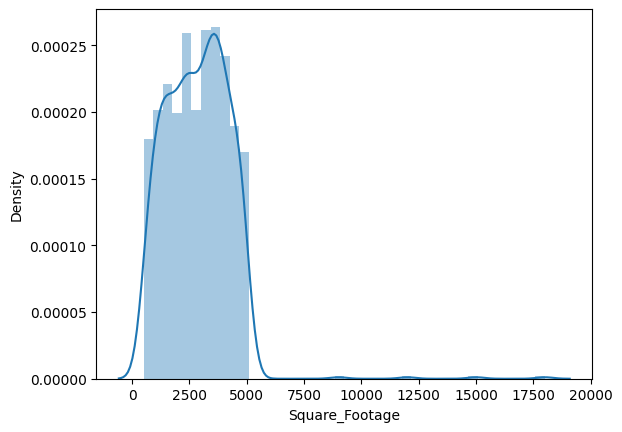

In [22]:
sns.distplot(df['Square_Footage'])
plt.show()

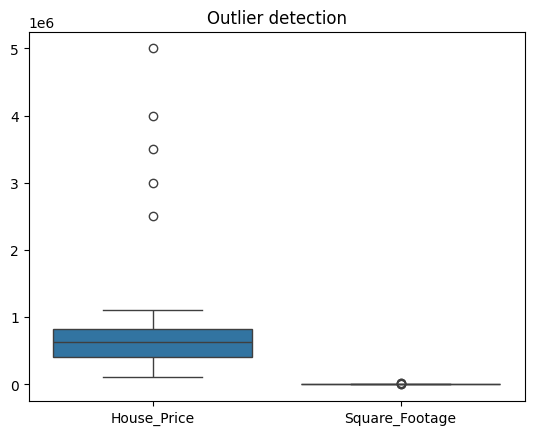

In [25]:
sns.boxplot(df[['House_Price','Square_Footage']])
plt.title("Outlier detection")
plt.show()

In [26]:
for col in ['House_Price','Square_Footage']:
  Q1 = df[col].quantile(0.25)
  Q3 = df[col].quantile(0.75)
  IQR = Q3-Q1

  lower = Q1-1.5*IQR
  upper = Q3+1.5*IQR

  df[col] = np.where(df[col]>upper,upper,np.where(df[col]<lower,lower,df[col]))

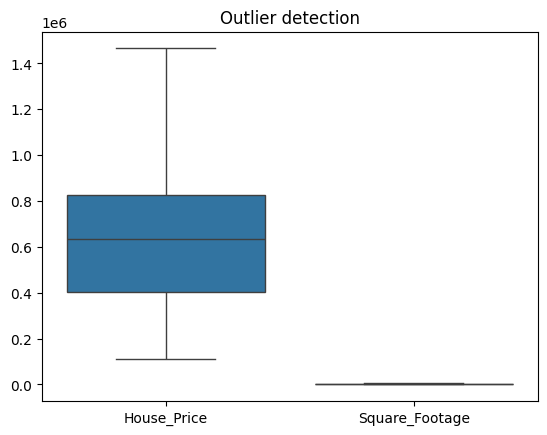

In [27]:
sns.boxplot(df[['House_Price','Square_Footage']])
plt.title("Outlier detection")
plt.show()

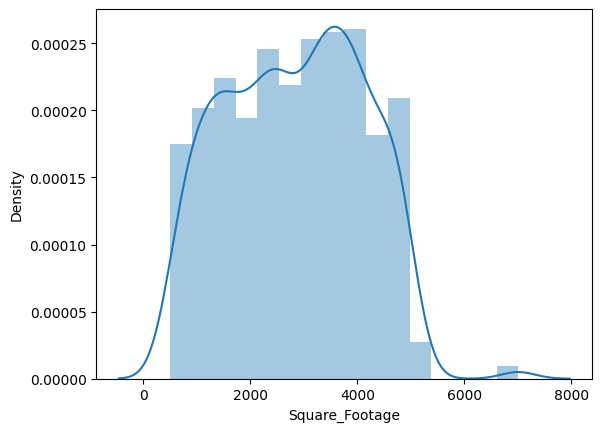

In [28]:
sns.distplot(df['Square_Footage'])
plt.show()

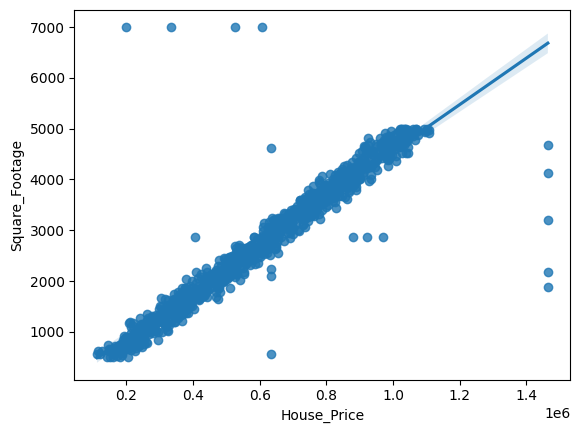

In [31]:
sns.regplot(x=df['House_Price'],y=df['Square_Footage'])
plt.show()

In [36]:
X = df.drop(['House_Price'],axis = 1)
y = df['House_Price']


In [37]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [38]:
from sklearn.linear_model import LinearRegression

# Exclude 'Student_ID' from training data, leaving only 'Square_Footage' as feature
X_train = X_train[['Square_Footage']]

model = LinearRegression()
model.fit(X_train, y_train)

LinearRegression()

In [40]:
y_pred = model.predict(X_test[['Square_Footage']])

In [41]:
results = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred})

print(results)

           Actual     Predicted
521  9.010005e+05  8.480224e+05
737  4.945375e+05  5.253000e+05
740  9.494042e+05  9.799934e+05
660  1.040389e+06  1.022467e+06
411  7.940100e+05  7.786238e+05
..            ...           ...
408  8.245296e+05  8.015670e+05
332  1.803936e+05  2.040945e+05
208  9.658167e+05  9.388473e+05
613  4.336642e+05  4.395946e+05
78   6.639050e+05  6.931080e+05

[200 rows x 2 columns]


In [42]:
from sklearn.metrics import mean_squared_error, r2_score

mse = mean_squared_error(y_test, y_pred)

r2 = r2_score(y_test, y_pred)

print("Mean Squared Error:", mse)

print("R-squared Score:", r2)

Mean Squared Error: 7048526537.632162
R-squared Score: 0.8906507676950459


In [44]:
new_house = pd.DataFrame({'Square_Footage': [6]})

predicted_House_Prices = model.predict(new_house)

print("Predicted House Prices:", predicted_House_Prices)

Predicted House Prices: [88430.20780357]


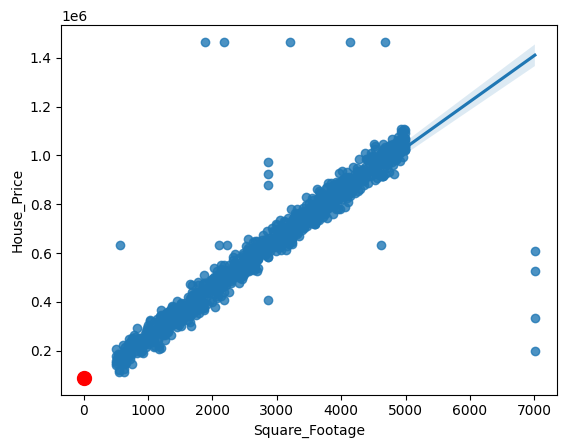

In [46]:
sns.regplot(x=df['Square_Footage'],y=df['House_Price'])

plt.scatter(new_house['Square_Footage'], predicted_House_Prices, color='red', marker='o', s=100)

plt.show()